In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random

from itertools import combinations
from sklearn.model_selection import ParameterGrid

from estimators import ConstantStepSizeEstimator, SampleAverageEstimator
from simulation import run_experiment_parallel

%load_ext autoreload
%autoreload 2

# $\epsilon$-greedy action-value method

## Does the pure greedy algorithm always converge to an average reward of 1 (for a stationary bandit)?

In [2]:
# Bandit parameters
epsilon = 0

# Simulation parameters
T = 1000  # number of timesteps played
R = 200  # number of runs to play in the simulation

In [3]:
# Define search space
variables = ["k", "q_true_var", "q_var"]
start_values = {
    "k": 10,
    "q_true_var": 1.0,
    "q_var": 1.0
}
var_names = {
    "k": "# Arms",
    "q_true_var": "Variance",
    "q_var": "Noise variance"
}

k_range = list(range(10, 201, 10))
q_true_var_range = np.round(np.arange(1.0, 3.01, 0.1), 1)
q_var_range = np.round(np.arange(0.0, 10.01, 0.5), 1)

scenarios = [
    {"k": k_range, "q_true_var": q_true_var_range, "q_var": [start_values["q_var"]]},
    {"k": k_range, "q_true_var": [start_values["q_true_var"]],             "q_var": q_var_range},
    {"k": [start_values["k"]],    "q_true_var": q_true_var_range,  "q_var": q_var_range},
]

In [4]:
%%time

try:
    len(limits.keys())
except NameError:
    limits = {}

for params in ParameterGrid(scenarios):
    key = (params["k"], params["q_true_var"], params["q_var"])

    # Skip already computed values
    if key in limits:
        continue

    result = run_experiment_parallel(
        R, T, params["k"], 
        q_true_var=params["q_true_var"], q_var=params["q_var"], 
        estimator=SampleAverageEstimator, 
        epsilon=epsilon
    )
    limits[key] = result["average_rewards"][-int(T/10):].mean().item()

df = pd.Series(limits).rename_axis(["k", "q_true_var", "q_var"]).reset_index(name="reward")

CPU times: user 3min 2s, sys: 18.6 s, total: 3min 21s
Wall time: 59min 37s


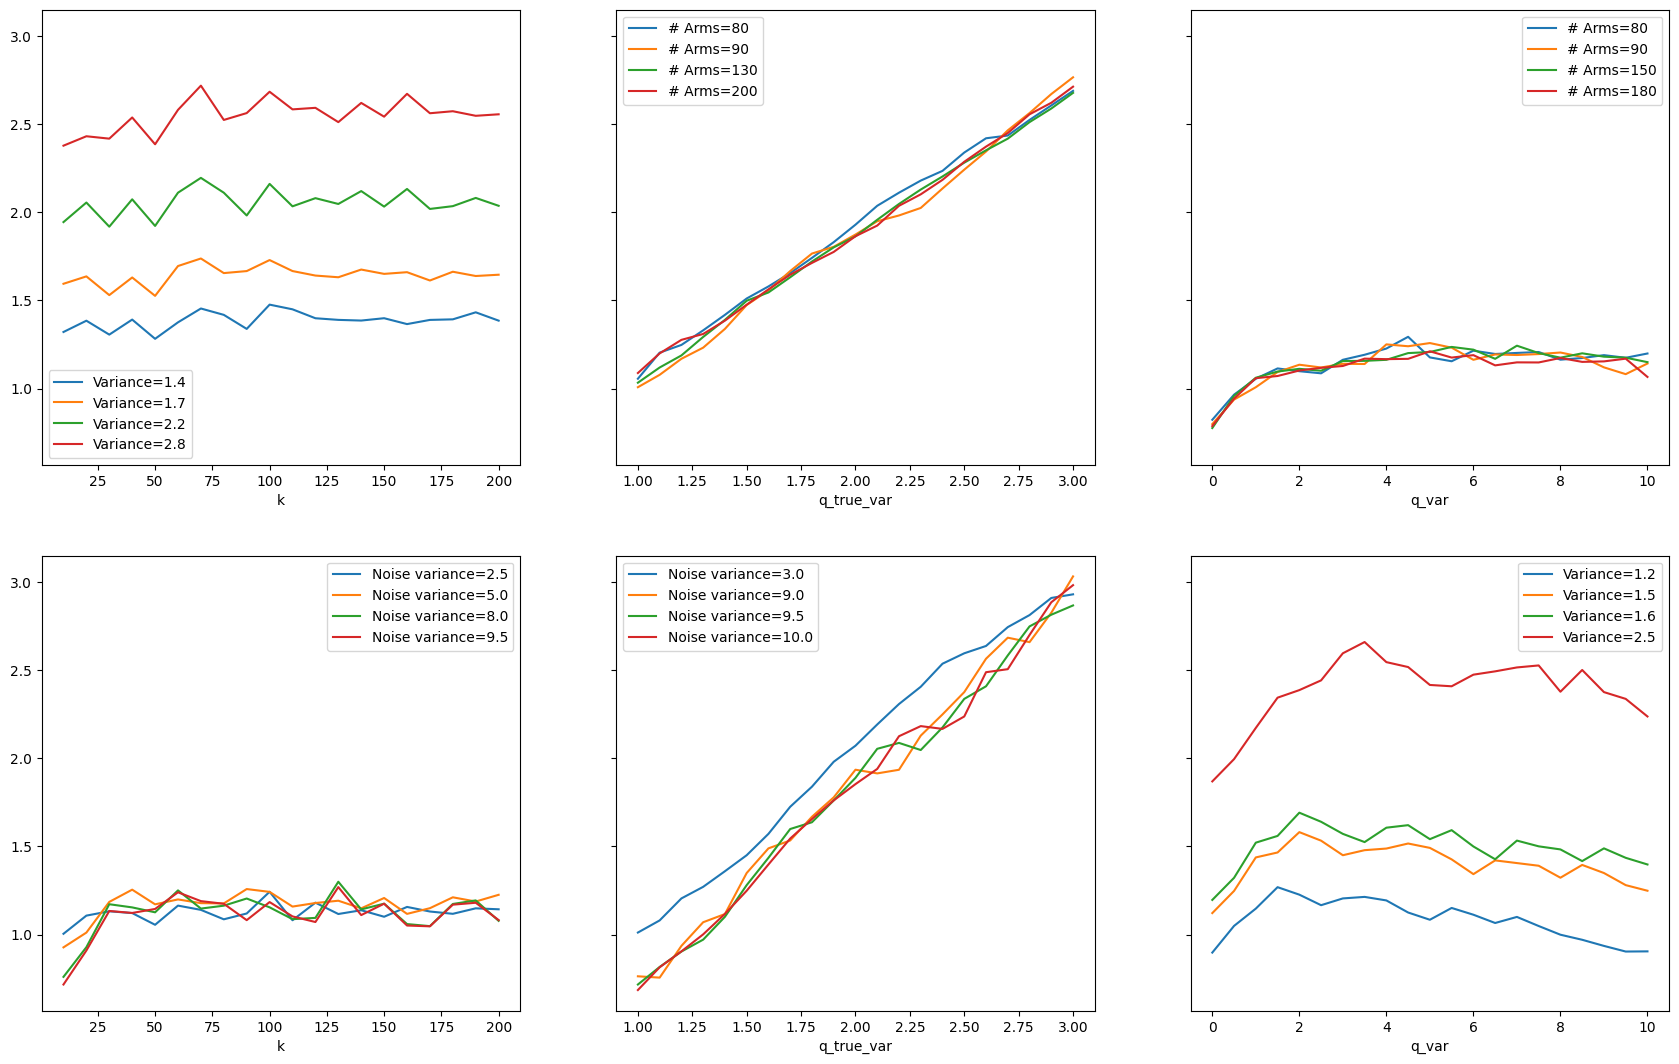

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(21, 13), sharey=True);

# Loop through all variables on x axis
for i, var1 in enumerate(variables):
    other_vars = [v for v in variables if v!=var1]

    # Loop through second variables for multiline plot
    for j, var2 in enumerate(other_vars):
        var3 = [v for v in variables if v not in (var1, var2)][0]
        var2_sample = sorted(random.sample(list(df[var2].unique()), 4))

        # Select data for this plot
        df_plot = df[(df[var3] == start_values[var3]) & df[var2].isin(var2_sample)]

        # Draw a line plot for each value of var2
        for val, group in df_plot.groupby(var2):
            group.sort_values(var1).plot(x=var1, y="reward", ax=axes[j,i], label=f"{var_names[var2]}={val}")

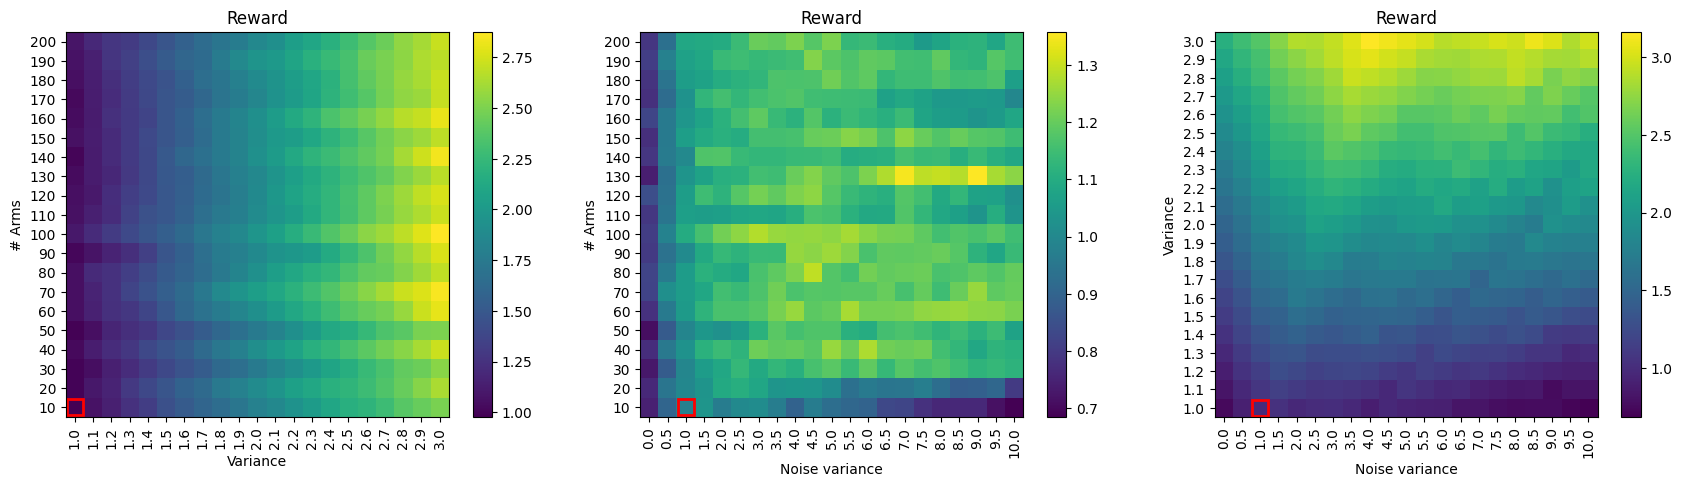

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))

for ax, (var1, var2) in zip(axes, combinations(variables, 2)):
    var3 = [v for v in variables if v not in (var1, var2)][0]

    # Reward as a function of var1 and var2
    df_plot = df[df[var3] == start_values[var3]].pivot(index=var1, columns=var2, values="reward")
    im = ax.imshow(df_plot, aspect="auto", cmap="viridis", origin="lower", interpolation='nearest')

    # tick labels from the pivot's index/columns
    ax.set_xticks(range(len(df_plot.columns)));
    ax.set_xticklabels(df_plot.columns, rotation=90);
    ax.set_xlabel(var_names[var2])
    ax.set_yticks(range(len(df_plot.index)));
    ax.set_yticklabels(df_plot.index);
    ax.set_ylabel(var_names[var1]);

    # Title, and colorbar
    ax.set_title("Reward")
    fig.colorbar(im)

    # Highlight the initial values
    # convert data coords -> pixel index and plot marker
    x_idx = df_plot.columns.get_loc(start_values[var2])
    y_idx = df_plot.index.get_loc(start_values[var1])
    ax.plot(x_idx, y_idx, marker="s", color="red", markersize=12, markeredgewidth=2, markerfacecolor="none")

## Non-Stationary k-armed Bandit

### Compare sample-average with constant step-size action-value methods

Average reward for sample average:  0.7037529671728684
Average reward for constant step size:  0.8696984433881544
CPU times: user 10.9 s, sys: 3.02 s, total: 13.9 s
Wall time: 2min 17s


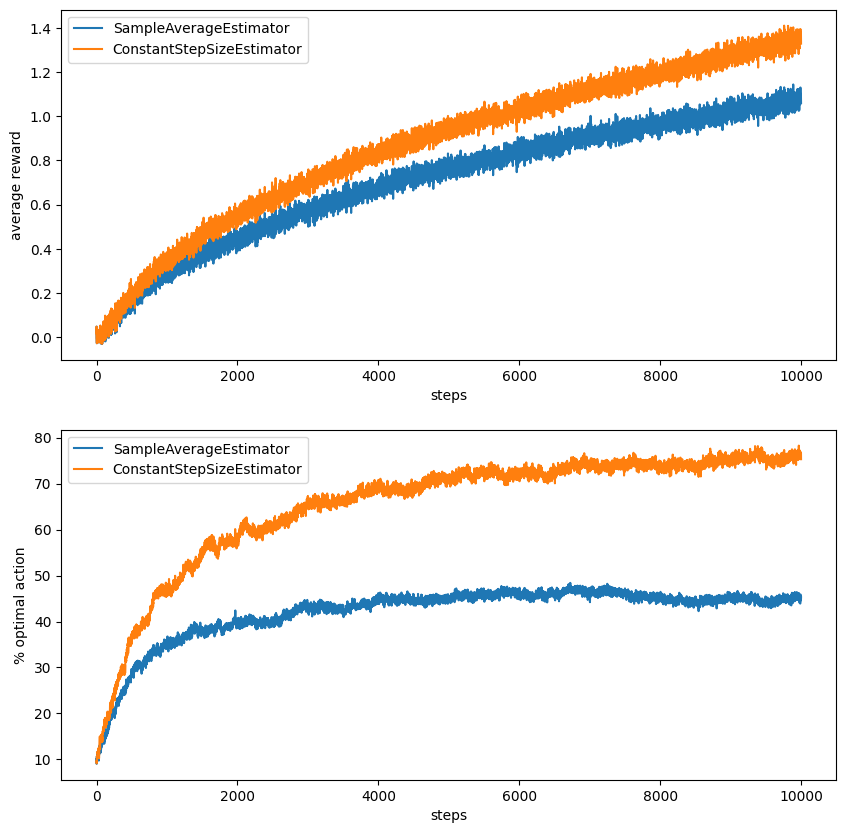

In [7]:
%%time

# Bandit parameters
k = 10  # number of arms in the bandit
q_true_mean = 0.0
q_true_var = 0.0
drift_var = 0.01

# Agent parameters
epsilon = 0.1
estimators = [SampleAverageEstimator, ConstantStepSizeEstimator]

# Simulation parameters
T = 10000  # number of timesteps played
R = 2000  # number of runs to play in the simulation

results = []

for i, estimator in enumerate(estimators):
    results.append(
        run_experiment_parallel(
            R, T, k, estimator, 
            q_true_mean=q_true_mean, q_true_var=q_true_var, drift_var=drift_var,
            epsilon=epsilon
        )
    )


print("Average reward for sample average: ", np.mean(results[0]["average_rewards"]))
print("Average reward for constant step size: ", np.mean(results[1]["average_rewards"]))


plt.figure(figsize=(10, 10))

plt.subplot(2, 1, 1)
for i, estimator in enumerate(estimators):
    plt.plot(results[i]["average_rewards"], label=estimator.__name__)
plt.xlabel("steps")
plt.ylabel("average reward")
plt.legend()

plt.subplot(2, 1, 2)
for i, estimator in enumerate(estimators):
    plt.plot(results[i]["percent_optimal_actions"], label=estimator.__name__)
plt.xlabel("steps")
plt.ylabel("% optimal action")
plt.legend()

plt.savefig('../images/figure_2_2_ns.png', bbox_inches="tight")